In [1]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [5]:
import os
print (os.getcwd())
print (os.listdir())

C:\Users\user
['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '.loggy3', '.virtual_documents', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'insurance_analysis.ipynb', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{7348ca12-d8e1-11ec-be72-080027ec4824}.TM.blf', 'NTUSER.DAT{7348ca12-d8e1-11ec-be72-080027ec4824}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{7348ca12-d8e1-11ec-be72-080027ec4824}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Recent', 'sales_analysis.ipynb', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Videos', 'WPS Cloud']


In [39]:
df=pd.read_csv(r'C:\Users\user\Downloads\archive\insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicates: 1


In [12]:
df=df.drop_duplicates()
df.shape

(1337, 7)

In [14]:
df.groupby('smoker')['charges'].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

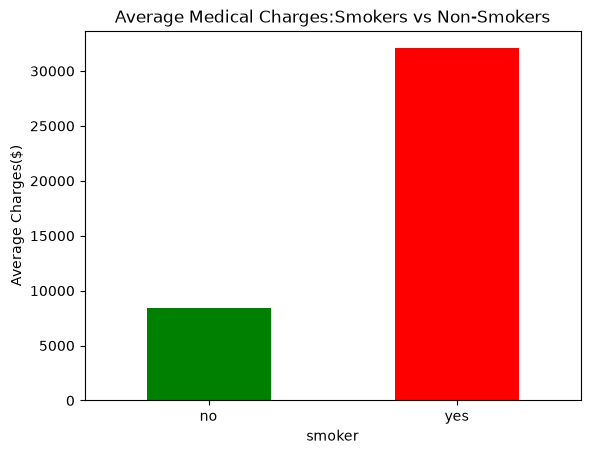

In [17]:
df.groupby('smoker')['charges'].mean().plot(kind='bar',color=['green','red'])
plt.title('Average Medical Charges:Smokers vs Non-Smokers')
plt.ylabel('Average Charges($)')
plt.xticks(rotation=0)
plt.show()

In [20]:
print("Duplicates:", df.duplicated().sum())
df=df.drop_duplicates()

Duplicates: 0


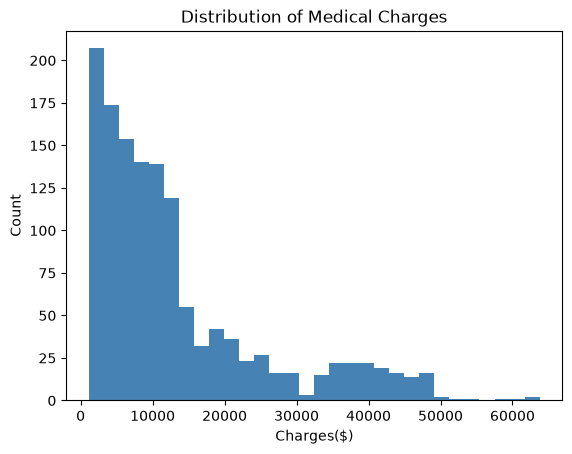

In [21]:
plt.hist(df['charges'],bins=30,color='steelblue')
plt.title('Distribution of Medical Charges')
plt.xlabel('Charges($)')
plt.ylabel('Count')
plt.show()

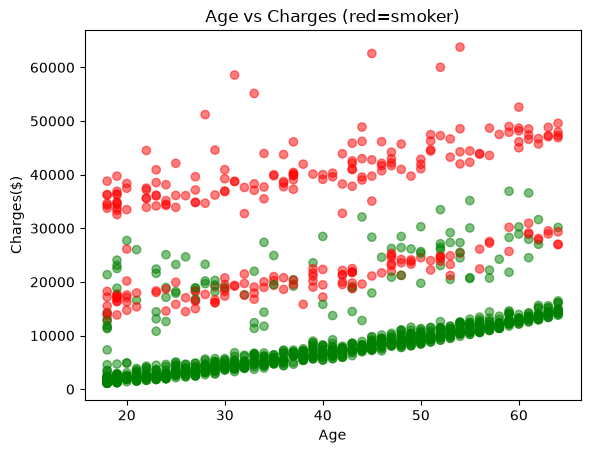

In [22]:
colors=df['smoker'].map({'yes':'red','no':'green'})
plt.scatter(df['age'],df['charges'],c=colors, alpha=0.5)
plt.title('Age vs Charges (red=smoker)')
plt.xlabel('Age')
plt.ylabel('Charges($)')
plt.show()

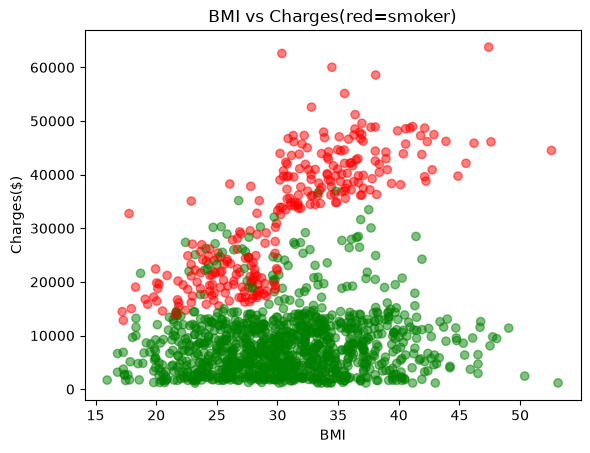

In [23]:
plt.scatter(df['bmi'],df['charges'], c=colors, alpha=0.5)
plt.title('BMI vs Charges(red=smoker)')
plt.xlabel('BMI')
plt.ylabel('Charges($)')
plt.show()

In [24]:
df['bmi_group']=pd.cut(df['bmi'],bins=[0,25,30,100], labels=['Under 25', '25-30', 'Over 30'])
print(df.groupby(['smoker', 'bmi_group'],observed=True)['charges'].mean().round(0))

smoker  bmi_group
no      Under 25      7547.0
        25-30         8226.0
        Over 30       8866.0
yes     Under 25     19839.0
        25-30        22491.0
        Over 30      41693.0
Name: charges, dtype: float64


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [27]:
X=pd.get_dummies(df.drop(columns=['charges', 'bmi_group']),drop_first=True)
y=df['charges']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [28]:
model=LinearRegression()
model.fit(X_train,y_train)
pred=model.predict(X_test)
print("R2:", round(r2_score(y_test,pred), 3))
print("Average error($):", round(mean_absolute_error(y_test,pred)))

R2: 0.807
Average error($): 4177


In [29]:
print(pd.Series(model.coef_,index=X.columns).sort_values(ascending=False).round(0))

smoker_yes          23078.0
children              533.0
bmi                   319.0
age                   248.0
sex_male             -102.0
region_northwest     -392.0
region_southwest     -659.0
region_southeast     -839.0
dtype: float64


In [35]:
X2=X.copy()
X2['obese']=(df['bmi']>=30).astype(int)
X2['smoker_obese']= X2['smoker_yes']*X2['obese']

X_train,X_test,y_train,y_test= train_test_split(X2, y, test_size = 0.2,random_state = 42)
model2= LinearRegression()
model2.fit(X_train,y_train)
pred2= model2.predict(X_test)
print("R2:",round(r2_score(y_test,pred2),3))
print("Average error ($):", round(mean_absolute_error(y_test,pred2)))

R2: 0.907
Average error ($): 2369


##Conclusions
-Smokers pay about 4x more than non-smokers on average ($32,050 vs about $8,400).
-Charges rise steadily with age for everyone.
-BMI over 30 raises costs sharply for smokers (about $22,500 to $41,700) but barely for non-smokers.
-A linear regression with a smoker-obese interaction feature explains 91% of the variation(R^2 = 0.907) with an average error of $2,369.